# Numerical Validation of an Optimal Switching Scheme
## Monte-Carlo regression vs. the explicit solution of Ly Vath & Pham (2007)

**Goal.** We implement a numerical scheme (backward Monte-Carlo regression) for the
finite-horizon optimal switching problem, and we validate it against a case where the
solution is known in **closed form**.

**Setting.**
- Theory of the switching problem: Djehiche, Hamadène & Popier (2007).
- Numerical scheme (regression Monte-Carlo): in the spirit of Carmona & Ludkovski (2005, 2007).
- Closed-form benchmark: Ly Vath & Pham (2007), Theorem 4.1, two-regime case 2)b).

**Test case (Th. 4.1, identical payoffs, different diffusions).**
Price follows a regime-dependent GBM, $dX = b_i X\,dt + \sigma_i X\,dW$, with identical
payoffs $f_1(x)=f_2(x)=x^\gamma$ ($0<\gamma<1$), switching costs $g_{12}>0$, $g_{21}\ge 0$,
and the standing condition $r>\max_i b_i$.

The benchmark is stated for an **infinite horizon**; the numerical scheme uses a long but
**finite** horizon $T$ (the discount $e^{-rT}$ makes the truncation negligible for $T$ large).


## 1. Parameters

All inputs are gathered here. Case 2)b) requires $K_2>K_1$, $g_{12}>0$, $g_{21}\ge 0$,
$r>\max(b_1,b_2)$ (checked automatically below).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

PARAMS = {
    "b":     [0.00, 0.05],   # drifts per regime (regime 2 has the higher drift)
    "sigma": [0.30, 0.20],   # volatilities per regime (different diffusions)
    "r":     0.15,           # discount rate (must be > max(b))
    "gamma": 0.5,            # payoff f(x) = x^gamma, 0 < gamma < 1
    "g":     [[0.0, 1.0],    # g[i][j] = switching cost from i to j
              [1.0, 0.0]],
}
NREG = 2
b, sigma = PARAMS["b"], PARAMS["sigma"]
r, gamma = PARAMS["r"], PARAMS["gamma"]
g = PARAMS["g"]
print("Parameters:", PARAMS)

Parameters: {'b': [0.0, 0.05], 'sigma': [0.3, 0.2], 'r': 0.15, 'gamma': 0.5, 'g': [[0.0, 1.0], [1.0, 0.0]]}


## 2. Closed-form benchmark (Ly Vath & Pham)

Characteristic roots of $rv - L_i v = 0$, with $L_i v = \tfrac12\sigma_i^2 x^2 v'' + b_i x v'$:
$$m^\pm_i = -\Big(\tfrac{b_i}{\sigma_i^2}-\tfrac12\Big)\pm\sqrt{\Big(\tfrac{b_i}{\sigma_i^2}-\tfrac12\Big)^2+\tfrac{2r}{\sigma_i^2}},\qquad m^-_i<0<1<m^+_i.$$

"No-switch" value $\hat V_i(x)=K_i x^\gamma$ with
$K_i = \big(r-b_i\gamma+\tfrac12\sigma_i^2\gamma(1-\gamma)\big)^{-1}$.

In case 2)b) the strong regime $j$ (larger $K$) never switches, while the weak regime $i$
switches to $j$ above a threshold $x^*_i$:
$$v_j(x)=K_j x^\gamma,\qquad
v_i(x)=\begin{cases}A\,x^{m^+_i}+K_i x^\gamma & x<x^*_i\\[2pt] K_j x^\gamma-g_{ij}& x\ge x^*_i\end{cases}$$
with $x^*_i$ and $A$ fixed by the continuity / smooth-fit ($C^1$) conditions at $x^*_i$.

In [2]:
def roots_m(b_i, s_i, r):
    a = b_i/s_i**2 - 0.5
    d = np.sqrt(a**2 + 2*r/s_i**2)
    return -a + d, -a - d                       # (m+, m-)

def K_coef(b_i, s_i, r, gamma):
    denom = r - b_i*gamma + 0.5*s_i**2*gamma*(1-gamma)
    return 1.0/denom

mp = [roots_m(b[i], sigma[i], r)[0] for i in range(NREG)]
K  = [K_coef(b[i], sigma[i], r, gamma) for i in range(NREG)]

# identify weak (small K) and strong (large K) regimes, check case 2b
i_weak, j_strong = (0, 1) if K[1] > K[0] else (1, 0)
assert r > max(b) and g[i_weak][j_strong] > 0 and g[j_strong][i_weak] >= 0, \
       "Parameters are not in case 2)b)."

def build_benchmark():
    i, j = i_weak, j_strong
    Ki, Kj, mpi, gij = K[i], K[j], mp[i], g[i][j]
    x_star = (mpi/(mpi-gamma) * gij/(Kj-Ki))**(1/gamma)
    A = (Kj-Ki)*gamma/mpi * x_star**(gamma-mpi)
    def v_strong(x): return Kj*np.asarray(x,float)**gamma
    def v_weak(x):
        x = np.asarray(x,float)
        return np.where(x < x_star,
                        A*x**mpi + Ki*x**gamma,
                        Kj*x**gamma - gij)
    return x_star, A, {i: v_weak, j: v_strong}

x_star, A_const, v_exact = build_benchmark()
print(f"weak regime = {i_weak+1}, strong regime = {j_strong+1}")
print(f"switching threshold x* = {x_star:.4f}")

weak regime = 1, strong regime = 2
switching threshold x* = 0.7191


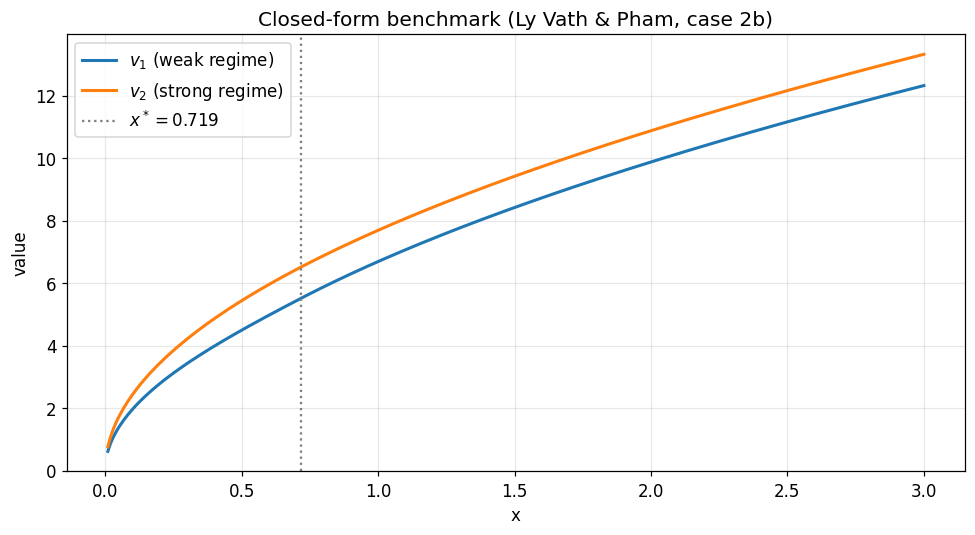

In [3]:
# Plot the benchmark value functions
xs = np.linspace(0.01, 3.0, 400)
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(xs, v_exact[i_weak](xs), lw=2, label=f"$v_{i_weak+1}$ (weak regime)")
ax.plot(xs, v_exact[j_strong](xs), lw=2, label=f"$v_{j_strong+1}$ (strong regime)")
ax.axvline(x_star, color='gray', ls=':', label=f"$x^*={x_star:.3f}$")
ax.set_xlabel("x"); ax.set_ylabel("value")
ax.set_title("Closed-form benchmark (Ly Vath & Pham, case 2b)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 3. Price simulation (regime-dependent GBM)

Exact log-Euler scheme. The Brownian shocks are drawn **once** and shared across regimes,
so the per-regime trajectories stay aligned (this matters for the switching decision below).

In [4]:
def simulate_all_regimes(X0, M, N, dt, b, sigma, rng):
    """Return X of shape (NREG, M+1, N): GBM paths per regime, common shocks."""
    Z = rng.standard_normal((M, N))
    X = np.empty((NREG, M+1, N))
    for i in range(NREG):
        drift = (b[i] - 0.5*sigma[i]**2)*dt
        vol   = sigma[i]*np.sqrt(dt)
        X[i, 0] = X0
        for m in range(M):
            X[i, m+1] = X[i, m]*np.exp(drift + vol*Z[m])
    return X

## 4. The numerical scheme (backward Monte-Carlo regression)

Backward dynamic programming on the state $(t, x, i)$. At each step, staying in regime $i$
is compared with switching to $j$ **at the current price** (a switch is instantaneous, so
the price does not move during it):
$$V^i(t,x)=\max\Big[\psi_i(x)\,dt+e^{-r\,dt}\,\mathbb E^i[V^i(t{+}dt)\mid x],\ \max_{j\ne i}\big(-g_{ij}+V^j(t,x)\big)\Big].$$

The continuation values are estimated by least-squares regression on a polynomial basis in
$\log X$. When evaluating $V^j$ at the current price of regime $i$, the price is **clipped to
the regression support** to avoid polynomial extrapolation (see Section 6).

In [8]:
def make_basis_logX(degree):
    def basis(x):
        lx = np.log(np.asarray(x, float))
        return np.vander(lx, N=degree+1, increasing=True)
    return basis

# --- Engine configuration (tweak M, N here depending on your machine) ---
CFG = {
    "T_horizon": 60.0,        # long horizon ~ infinite (e^{-rT} negligible)
    "M":         6000,        # time steps   (raise to 6000 for more accuracy)
    "N":         40_000,      # paths        (raise to 40000 for more accuracy)
    "basis":     make_basis_logX(4),
}

def run_switching(X0, cfg, params, rng):
    """Backward Monte-Carlo regression. Returns V^i(0, X0) for each regime."""
    T, M, N = cfg["T_horizon"], cfg["M"], cfg["N"]
    dt   = T/M
    disc = np.exp(-params["r"]*dt)
    basis = cfg["basis"]
    g = params["g"]
    X = simulate_all_regimes(X0, M, N, dt, params["b"], params["sigma"], rng)

    def fit(x, y):
        Phi = basis(x); c, *_ = np.linalg.lstsq(Phi, y, rcond=None); return c
    def evalc(c, x): return basis(x) @ c

    Y = np.zeros((NREG, N))                          # terminal Y^i_T = 0
    for m in range(M-1, -1, -1):
        cont_stay = [evalc(fit(X[j,m], Y[j]), X[j,m]) for j in range(NREG)]
        coef_V    = [fit(X[j,m], Y[j]) for j in range(NREG)]
        lo = [X[j,m].min() for j in range(NREG)]     # regression support bounds
        hi = [X[j,m].max() for j in range(NREG)]
        Y_new = np.empty((NREG, N))
        for i in range(NREG):
            x_cur = X[i,m]
            cand = []
            for j in range(NREG):
                if j == i:                                   # stay
                    cand.append((x_cur**params["gamma"])*dt + disc*cont_stay[i])
                else:                                        # switch at current price
                    x_eval = np.clip(x_cur, lo[j], hi[j])    # avoid extrapolation
                    cand.append(-g[i][j] + evalc(coef_V[j], x_eval))
            Y_new[i] = np.stack(cand).max(axis=0)
        Y = Y_new
    return Y.mean(axis=1)

## 5. Validation

Numerical value vs. closed-form benchmark, across a range of initial prices $X_0$.

In [9]:
X0_grid = np.linspace(0.3, 2.5, 8)
print(f"{'X0':>6} | {'weak num':>9} {'exact':>8} {'err%':>6} | "
      f"{'strong num':>10} {'exact':>8} {'err%':>6}")
rows = []
for X0v in X0_grid:
    vn = run_switching(X0v, CFG, PARAMS, np.random.default_rng(1))
    ve = np.array([v_exact[i](X0v) for i in range(NREG)])
    ew = abs(vn[i_weak]-ve[i_weak])/ve[i_weak]*100
    es = abs(vn[j_strong]-ve[j_strong])/ve[j_strong]*100
    rows.append((X0v, vn[i_weak], ve[i_weak], vn[j_strong], ve[j_strong]))
    print(f"{X0v:>6.2f} | {vn[i_weak]:>9.4f} {ve[i_weak]:>8.4f} {ew:>6.2f} | "
          f"{vn[j_strong]:>10.4f} {ve[j_strong]:>8.4f} {es:>6.2f}")
rows = np.array(rows)

    X0 |  weak num    exact   err% | strong num    exact   err%
  0.30 |    3.4441   3.4293   0.43 |     4.2217   4.2133   0.20
  0.61 |    5.0619   5.0417   0.40 |     6.0406   6.0290   0.19
  0.93 |    6.4287   6.4125   0.25 |     7.4272   7.4125   0.20
  1.24 |    7.5943   7.5757   0.25 |     8.5926   8.5757   0.20
  1.56 |    8.6198   8.5989   0.24 |     9.6179   9.5989   0.20
  1.87 |    9.5458   9.5231   0.24 |    10.5437  10.5231   0.20
  2.19 |   10.3972  10.3724   0.24 |    11.3949  11.3724   0.20
  2.50 |   11.1891  11.1626   0.24 |    12.1867  12.1626   0.20


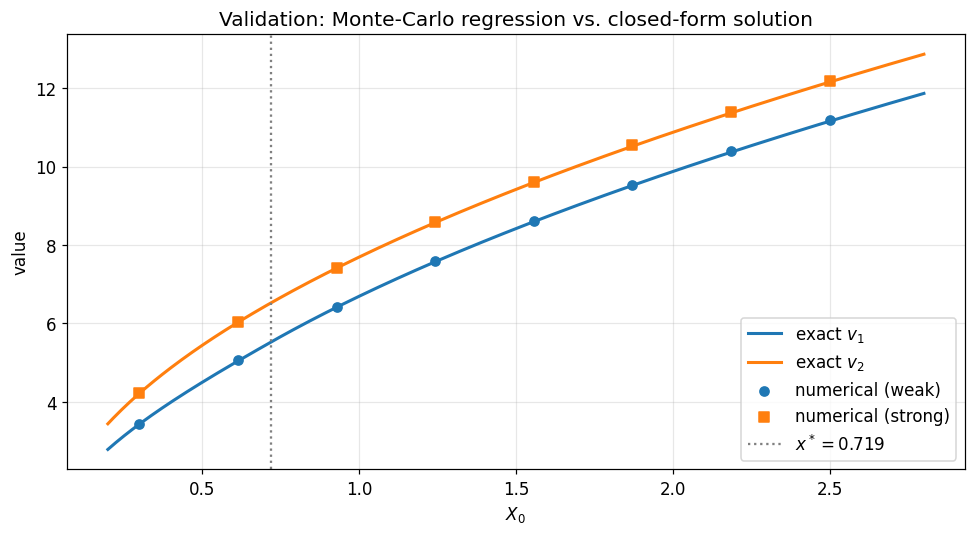

In [10]:
# Numerical (markers) vs exact (lines)
xs = np.linspace(0.2, 2.8, 300)
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(xs, v_exact[i_weak](xs), lw=2, label=f"exact $v_{i_weak+1}$")
ax.plot(xs, v_exact[j_strong](xs), lw=2, label=f"exact $v_{j_strong+1}$")
ax.scatter(rows[:,0], rows[:,1], marker='o', zorder=5, label="numerical (weak)")
ax.scatter(rows[:,0], rows[:,3], marker='s', zorder=5, label="numerical (strong)")
ax.axvline(x_star, color='gray', ls=':', label=f"$x^*={x_star:.3f}$")
ax.set_xlabel("$X_0$"); ax.set_ylabel("value")
ax.set_title("Validation: Monte-Carlo regression vs. closed-form solution")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 6. Notes on the numerical difficulties (brief)

Three points required care to obtain a stable, accurate scheme:

1. **Finite-horizon truncation.** The benchmark is infinite-horizon; the scheme is finite-horizon
   with terminal value $0$. The horizon must satisfy $e^{-rT}\ll 1$ (here $T\gtrsim 5/r\approx 33$;
   we use $T=60$). Too short a horizon causes a systematic downward bias.

2. **Regression basis.** Polynomials in $X$ are badly conditioned for a lognormal process over a
   long horizon ($X^k$ becomes huge on extreme paths), causing numerical blow-up. A basis in
   $\log X$ is well conditioned.

3. **Switching decision / extrapolation.** The switch is evaluated at the *current* price; the
   value function of the target regime must be read at that price. Evaluating a regression
   outside its fitted support leads to polynomial extrapolation and instability, so the price is
   clipped to the support before evaluation.

**Next steps:** convergence study (error vs. $N$, $dt$, $T$); a second closed-form benchmark
(Ly Vath & Pham, case 4.2); application to the storage problem with inventory (Carmona).

In [11]:
# ============================================================
# 7. Convergence study
# ============================================================
# Rigour where it matters:
#  - error measured at TWO prices: X0=0.5 (continuation) and X0=1.0 (switching),
#    averaged over both regimes -> convergence is location-independent;
#  - averaged over several seeds ONLY for the Monte-Carlo (vs N) curve, since
#    that error is random; vs dt and vs T are ~deterministic (n_rep=1).
# Reuses run_switching, v_exact, CFG, PARAMS, NREG.

from tqdm.auto import tqdm

X0_below, X0_above = 0.5, 1.0          # below / above the threshold x* = 0.719
X0_pts = [X0_below, X0_above]

def rel_err(cfg, n_rep=1, seed0=0, show=False):
    """Mean relative error over both regimes and both test prices."""
    errs = []
    it = tqdm(total=len(X0_pts)*n_rep, desc="  runs", leave=False) if show else None
    for X0v in X0_pts:
        ve = np.array([v_exact[i](X0v) for i in range(NREG)])
        for k in range(n_rep):
            vn = run_switching(X0v, cfg, PARAMS, np.random.default_rng(seed0 + k))
            errs.append(np.abs(vn - ve) / ve)
            if it: it.update(1)
    if it: it.close()
    return float(np.mean(errs))

# --- (a) vs N : Monte-Carlo error (random -> n_rep=3) ---
N_list = [2000, 5000, 10000, 20000, 40000]
err_N = [rel_err(dict(CFG, N=n), n_rep=3) for n in tqdm(N_list, desc="vs N")]

# --- (b) vs dt (=T/M) : time discretisation (n_rep=1) ---
M_list = [500, 1000, 2000, 4000]
err_M = [rel_err(dict(CFG, M=m)) for m in tqdm(M_list, desc="vs dt")]

# --- (c) vs T : horizon truncation (n_rep=1) ---
T_list = [10, 20, 30, 45, 60]
err_T = [rel_err(dict(CFG, T_horizon=t, M=int(t*100))) for t in tqdm(T_list, desc="vs T")]

print("err vs N :", dict(zip(N_list, np.round(err_N, 4))))
print("err vs M :", dict(zip(M_list, np.round(err_M, 4))))
print("err vs T :", dict(zip(T_list, np.round(err_T, 4))))

vs N:   0%|          | 0/5 [00:00<?, ?it/s]

vs dt:   0%|          | 0/4 [00:00<?, ?it/s]

vs T:   0%|          | 0/5 [00:00<?, ?it/s]

err vs N : {2000: np.float64(0.0077), 5000: np.float64(0.0041), 10000: np.float64(0.0032), 20000: np.float64(0.0039), 40000: np.float64(0.0034)}
err vs M : {500: np.float64(0.0094), 1000: np.float64(0.0042), 2000: np.float64(0.0021), 4000: np.float64(0.0014)}
err vs T : {10: np.float64(0.255), 20: np.float64(0.0726), 30: np.float64(0.0192), 45: np.float64(0.0014), 60: np.float64(0.0014)}


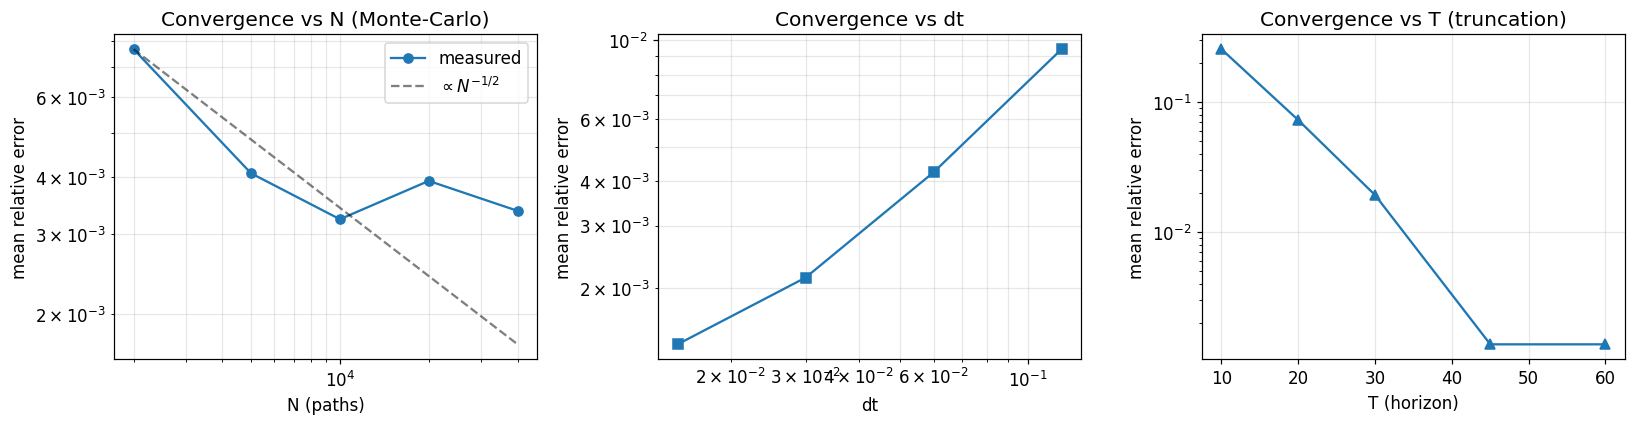

In [12]:
# --- Figures ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) vs N, log-log, with N^{-1/2} reference slope
axes[0].loglog(N_list, err_N, 'o-', label="measured")
ref = err_N[0] * np.sqrt(N_list[0]) / np.sqrt(N_list)
axes[0].loglog(N_list, ref, 'k--', alpha=.5, label=r"$\propto N^{-1/2}$")
axes[0].set_xlabel("N (paths)"); axes[0].set_ylabel("mean relative error")
axes[0].set_title("Convergence vs N (Monte-Carlo)")
axes[0].legend(); axes[0].grid(alpha=.3, which='both')

# (b) vs dt, log-log
dt_list = [CFG["T_horizon"]/m for m in M_list]
axes[1].loglog(dt_list, err_M, 's-')
axes[1].set_xlabel("dt"); axes[1].set_ylabel("mean relative error")
axes[1].set_title("Convergence vs dt"); axes[1].grid(alpha=.3, which='both')

# (c) vs T, semilog (truncation ~ e^{-rT})
axes[2].semilogy(T_list, err_T, '^-')
axes[2].set_xlabel("T (horizon)"); axes[2].set_ylabel("mean relative error")
axes[2].set_title("Convergence vs T (truncation)"); axes[2].grid(alpha=.3)

plt.tight_layout(); plt.show()

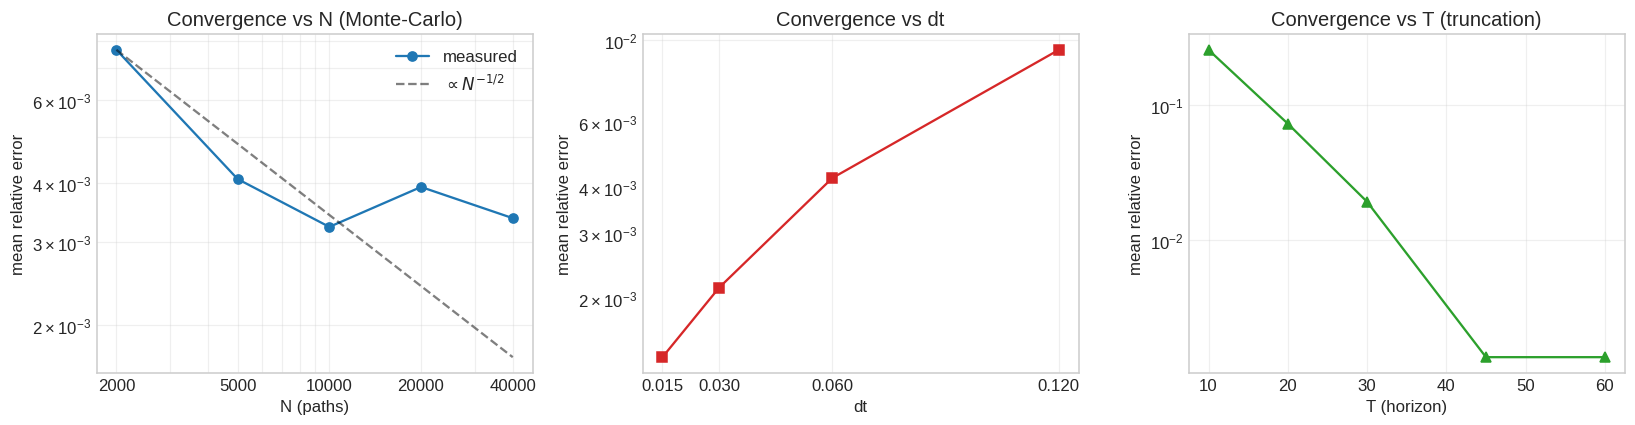

In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# -------------------------
# (a) vs N (Monte-Carlo)
# -------------------------
axes[0].loglog(N_list, err_N, 'o-', color="#1f77b4", label="measured")

ref = err_N[0] * np.sqrt(N_list[0]) / np.sqrt(N_list)
axes[0].loglog(N_list, ref, 'k--', alpha=.5, label=r"$\propto N^{-1/2}$")

axes[0].set_xlabel("N (paths)")
axes[0].set_ylabel("mean relative error")
axes[0].set_title("Convergence vs N (Monte-Carlo)")
axes[0].legend()
axes[0].grid(alpha=.3, which='both')

# --- afficher toutes les abscisses N_list ---
axes[0].set_xticks(N_list)
axes[0].get_xaxis().set_major_formatter(mticker.ScalarFormatter())
axes[0].ticklabel_format(style='plain', axis='x')

# -------------------------
# (b) vs dt  (x normal, y log)
# -------------------------
dt_list = [CFG["T_horizon"]/m for m in M_list]

axes[1].semilogy(dt_list, err_M, 's-', color="#d62728")
axes[1].set_xlabel("dt")
axes[1].set_ylabel("mean relative error")
axes[1].set_title("Convergence vs dt")
axes[1].grid(alpha=.3)

# --- ticks propres ---
axes[1].set_xticks(dt_list)
axes[1].ticklabel_format(style='plain', axis='x')

# -------------------------
# (c) vs T (truncation)
# -------------------------
axes[2].semilogy(T_list, err_T, '^-', color="#2ca02c")
axes[2].set_xlabel("T (horizon)")
axes[2].set_ylabel("mean relative error")
axes[2].set_title("Convergence vs T (truncation)")
axes[2].grid(alpha=.3)

plt.tight_layout()
plt.show()


In [14]:
import pandas as pd

# Table 1 : Convergence vs N
df_N = pd.DataFrame({
    "N": N_list,
    "mean_relative_error": err_N
})
print("\n=== Table: Convergence vs N ===")
print(df_N.to_string(index=False))

# Table 2 : Convergence vs dt
df_dt = pd.DataFrame({
    "dt": dt_list,
    "mean_relative_error": err_M
})
print("\n=== Table: Convergence vs dt ===")
print(df_dt.to_string(index=False))

# Table 3 : Convergence vs T
df_T = pd.DataFrame({
    "T_horizon": T_list,
    "mean_relative_error": err_T
})
print("\n=== Table: Convergence vs T ===")
print(df_T.to_string(index=False))



=== Table: Convergence vs N ===
    N  mean_relative_error
 2000             0.007660
 5000             0.004081
10000             0.003232
20000             0.003926
40000             0.003373

=== Table: Convergence vs dt ===
   dt  mean_relative_error
0.120             0.009434
0.060             0.004243
0.030             0.002142
0.015             0.001389

=== Table: Convergence vs T ===
 T_horizon  mean_relative_error
        10             0.255013
        20             0.072621
        30             0.019232
        45             0.001366
        60             0.001366


**Reading the convergence curves.** Error measured at $X_0=0.5$ (continuation region)
and $X_0=1.0$ (switching region), averaged over both regimes; the Monte-Carlo curve is
averaged over 3 seeds.

- **vs $N$**: decreases approximately like $N^{-1/2}$ (Monte-Carlo rate), then flattens
  onto a floor set by the time-discretisation and regression-basis biases.
- **vs $dt$**: decreases as $dt\to 0$, limited by the same floor.
- **vs $T$**: drops quickly then plateaus around $T\approx 30$, confirming the rule
  $T\gtrsim 5/r$ for the finite-horizon approximation of the infinite-horizon benchmark.